In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

data = {
    "Date": [
        "2026-01-01", "2026-01-03", "2026-01-05", "2026-01-07",
        "2026-01-09", "2026-01-11", "2026-01-13", "2026-01-15",
        "2026-01-17", "2026-01-19", "2026-01-21", "2026-01-23",
        "2026-01-25", "2026-01-27", "2026-01-29"
    ],
    "Product": [
        "Laptop", "Phone", "Headphones", "Laptop", "Phone",
        "Tablet", "Laptop", "Headphones", "Phone", "Tablet",
        "Laptop", "Phone", "Headphones", "Tablet", "Laptop"
    ],
    "Category": [
        "Electronics", "Electronics", "Accessories", "Electronics",
        "Electronics", "Electronics", "Electronics", "Accessories",
        "Electronics", "Electronics", "Electronics", "Electronics",
        "Accessories", "Electronics", "Electronics"
    ],
    "Region": [
        "West", "North", "West", "South", "North",
        "East", "West", "South", "East", "North",
        "South", "West", "North", "East", "West"
    ],
    "Quantity": [2, 5, 10, 1, 4, 3, 2, 8, 6, 2, 3, 5, 12, 4, 2],
    "Sales": [
        100000, 75000, 10000, 50000, 60000,
        45000, 100000, 8000, 90000, 30000,
        150000, 75000, 12000, 60000, 100000
    ]
}

df = pd.DataFrame(data)
df["Date"] = pd.to_datetime(df["Date"])

print("Dataset loaded successfully!")
df.head()

Dataset loaded successfully!


,Date,Product,Category,Region,Quantity,Sales
0,2026-01-01,Laptop,Electronics,West,2,100000
1,2026-01-03,Phone,Electronics,North,5,75000
2,2026-01-05,Headphones,Accessories,West,10,10000
3,2026-01-07,Laptop,Electronics,South,1,50000
4,2026-01-09,Phone,Electronics,North,4,60000


In [2]:
print("Dataset size:", df.shape)

print("\nColumn names:")
print(df.columns)

print("\nDataset information:")
df.info()

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

Dataset size: (15, 6)

Column names:
Index(['Date', 'Product', 'Category', 'Region', 'Quantity', 'Sales'], dtype='object')

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   Date      15 non-null     datetime64[ns]
 1   Product   15 non-null     object        
 2   Category  15 non-null     object        
 3   Region    15 non-null     object        
 4   Quantity  15 non-null     int64         
 5   Sales     15 non-null     int64         
dtypes: datetime64[ns](1), int64(2), object(3)
memory usage: 852.0+ bytes

Missing values:
Date        0
Product     0
Category    0
Region      0
Quantity    0
Sales       0
dtype: int64

Duplicate rows: 0


In [3]:
df.describe()

,Date,Quantity,Sales
count,15,15.000000,15.000000
mean,2026-01-15 00:00:00,4.600000,64333.333333
min,2026-01-01 00:00:00,1.000000,8000.000000
25%,2026-01-08 00:00:00,2.000000,37500.000000
50%,2026-01-15 00:00:00,4.000000,60000.000000
75%,2026-01-22 00:00:00,5.500000,95000.000000
max,2026-01-29 00:00:00,12.000000,150000.000000
std,NaN,3.202677,40268.148822


In [4]:
print("Total sales:", df["Sales"].sum())
print("Average sales:", df["Sales"].mean())
print("Maximum sales:", df["Sales"].max())
print("Minimum sales:", df["Sales"].min())

Total sales: 965000
Average sales: 64333.333333333336
Maximum sales: 150000
Minimum sales: 8000


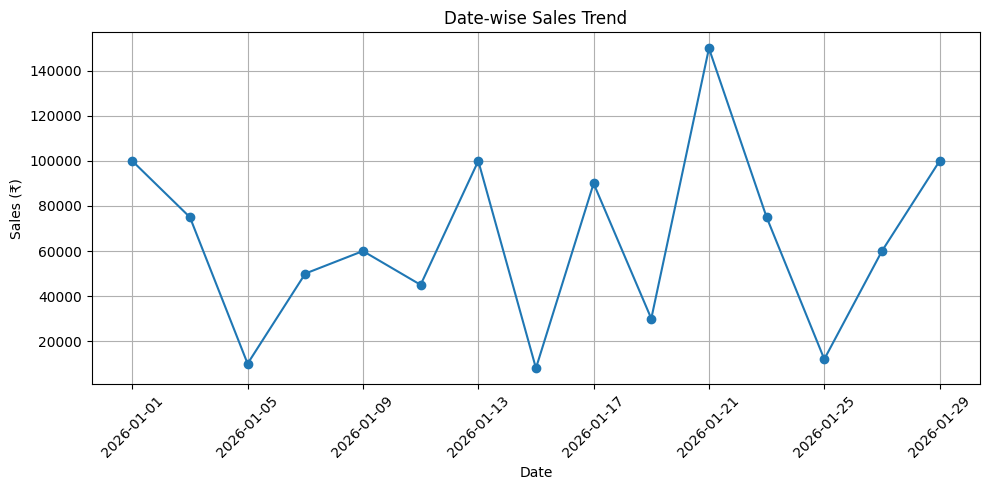

In [5]:
daily_sales = df.groupby("Date")["Sales"].sum()

plt.figure(figsize=(10, 5))
plt.plot(daily_sales.index, daily_sales.values, marker="o")

plt.title("Date-wise Sales Trend")
plt.xlabel("Date")
plt.ylabel("Sales (₹)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

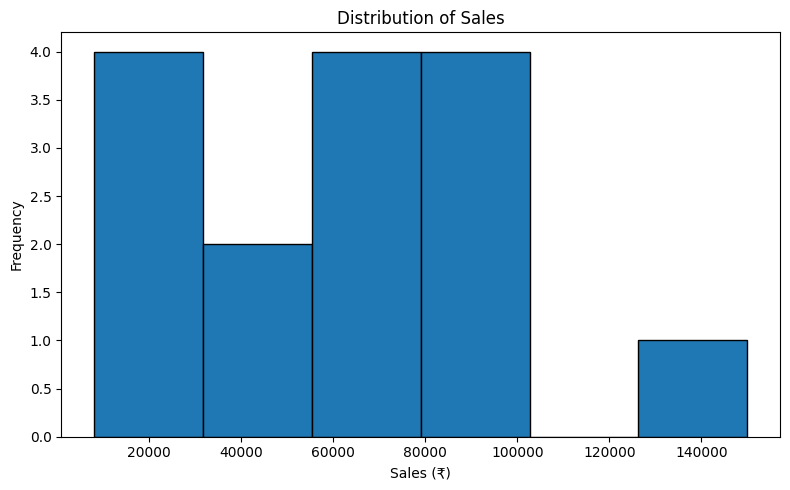

In [6]:
plt.figure(figsize=(8, 5))
plt.hist(df["Sales"], bins=6, edgecolor="black")

plt.title("Distribution of Sales")
plt.xlabel("Sales (₹)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

Product
Headphones     30000
Laptop        500000
Phone         300000
Tablet        135000
Name: Sales, dtype: int64


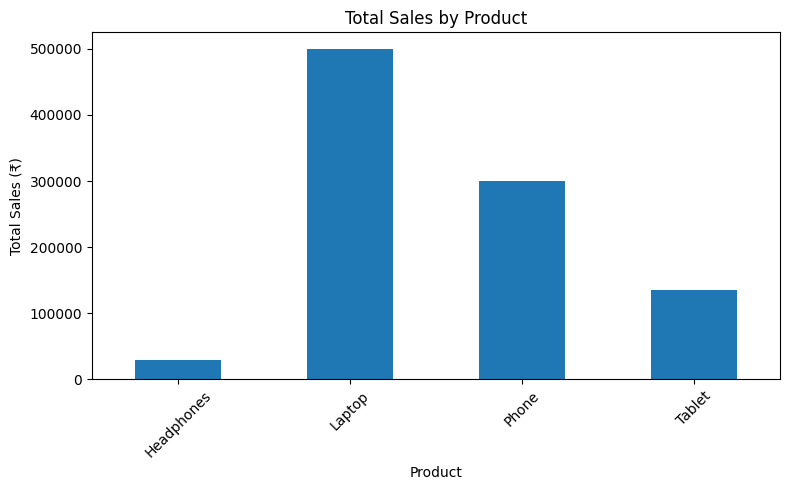

In [7]:
product_sales = df.groupby("Product")["Sales"].sum()
print(product_sales)

product_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Total Sales by Product")
plt.xlabel("Product")
plt.ylabel("Total Sales (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Region
East     195000
North    177000
South    208000
West     385000
Name: Sales, dtype: int64


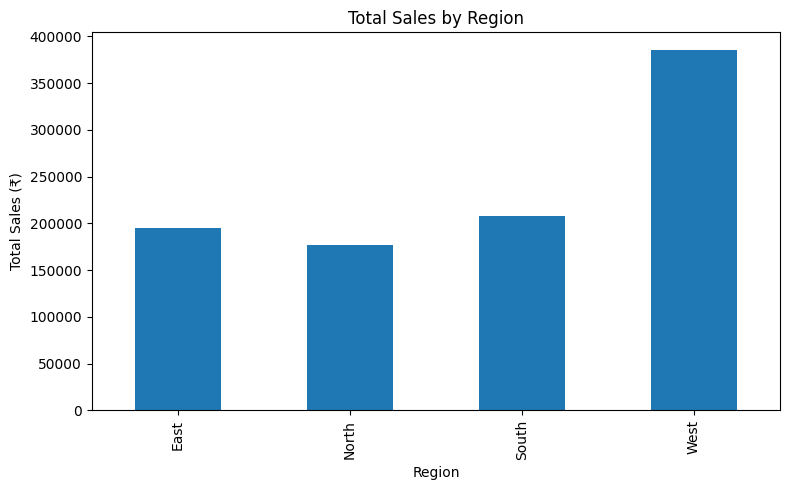

In [8]:
region_sales = df.groupby("Region")["Sales"].sum()
print(region_sales)

region_sales.plot(kind="bar", figsize=(8, 5))
plt.title("Total Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales (₹)")
plt.tight_layout()
plt.show()

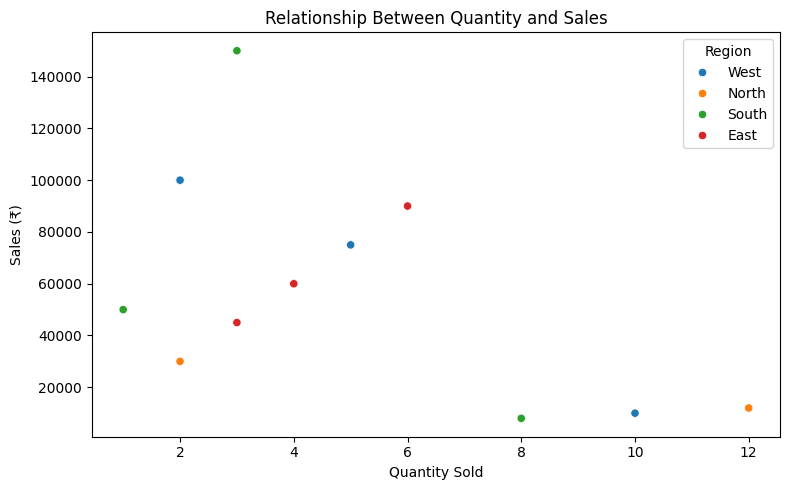

In [9]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Quantity", y="Sales", hue="Region")

plt.title("Relationship Between Quantity and Sales")
plt.xlabel("Quantity Sold")
plt.ylabel("Sales (₹)")
plt.tight_layout()
plt.show()

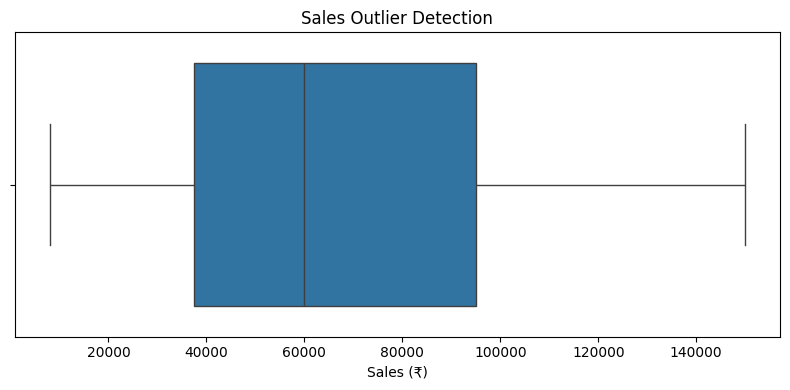

In [10]:
plt.figure(figsize=(8, 4))
sns.boxplot(x=df["Sales"])

plt.title("Sales Outlier Detection")
plt.xlabel("Sales (₹)")
plt.tight_layout()
plt.show()

In [11]:
Q1 = df["Sales"].quantile(0.25)
Q3 = df["Sales"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

outliers = df[
    (df["Sales"] < lower_limit) |
    (df["Sales"] > upper_limit)
]

print("Potential outliers:")
print(outliers)

Potential outliers:
Empty DataFrame
Columns: [Date, Product, Category, Region, Quantity, Sales]
Index: []


In [12]:
print("1. Which product has the highest sales?")
print(df.groupby("Product")["Sales"].sum().idxmax())

print("\n2. Which region has the highest sales?")
print(df.groupby("Region")["Sales"].sum().idxmax())

print("\n3. Which product has the highest quantity sold?")
print(df.groupby("Product")["Quantity"].sum().idxmax())

print("\n4. What is the average sales value?")
print(df["Sales"].mean())

1. Which product has the highest sales?
Laptop

2. Which region has the highest sales?
West

3. Which product has the highest quantity sold?
Headphones

4. What is the average sales value?
64333.333333333336
